# Exercise 6 – Direct Monte Carlo sampling of the Boltzmann distribution

**Week 2 · Monte Carlo sampling**

A particle in a harmonic potential $V(x) = \tfrac12 k x^2$ at temperature
$k_BT$ is found at position $x$ with probability

$$P(x) = \frac{e^{-V(x)/k_BT}}{Z}, \qquad Z = \int e^{-V(x)/k_BT}\,dx .$$

**Rejection sampling**: draw $x$ uniformly, and keep it with probability
$e^{-(V(x)-V_\text{min})/k_BT}$. The kept points are distributed according to
$P(x)$, so thermal averages become simple sample means. We compare
$\langle V\rangle$ from sampling with the exact integral (equipartition gives
$\langle V \rangle = k_BT/2$).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.montecarlo import boltzmann_pdf, rejection_sample, thermal_average
from comphy.plotting import annotate, setup_axes

rng = np.random.default_rng(0)


def harmonic(k=1.0, x0=0.0):
    return lambda x: 0.5 * k * (np.asarray(x) - x0) ** 2

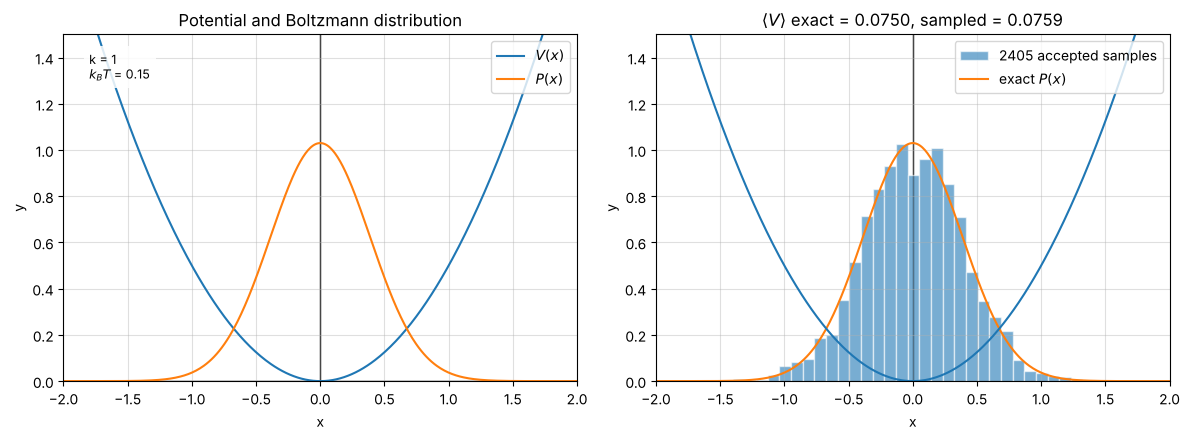

acceptance ratio: 24.1%


In [2]:
V, kT, lims = harmonic(k=1), 0.15, (-2, 2)
xs = np.linspace(*lims, 400)
pdf = boltzmann_pdf(V, kT, lims)
sample = rejection_sample(V, kT, lims, n_trials=10_000, rng=rng)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(xs, V(xs), label="$V(x)$")
axes[0].plot(xs, pdf(xs), label="$P(x)$")
annotate(axes[0], f"k = 1\n$k_BT$ = {kT}")
setup_axes(axes[0], xlim=lims, ylim=(0, 1.5), title="Potential and Boltzmann distribution")
axes[0].legend(loc="upper right")

axes[1].hist(sample, bins=30, density=True, color="C0", alpha=0.6, edgecolor="white",
             label=f"{len(sample)} accepted samples")
axes[1].plot(xs, pdf(xs), color="C1", label="exact $P(x)$")
axes[1].plot(xs, V(xs), color="C0")
setup_axes(axes[1], xlim=lims, ylim=(0, 1.5),
           title=f"$\\langle V\\rangle$ exact = {thermal_average(V, kT, lims):.4f}, "
                 f"sampled = {V(sample).mean():.4f}")
axes[1].legend(loc="upper right")
fig.tight_layout()
plt.show()

print(f"acceptance ratio: {len(sample) / 10_000:.1%}")

## Changing the temperature
Stiffer spring ($k = 5$) and six temperatures. Higher temperature spreads the
particle over a wider range, and $\langle V\rangle = k_BT/2$ independently of $k$.

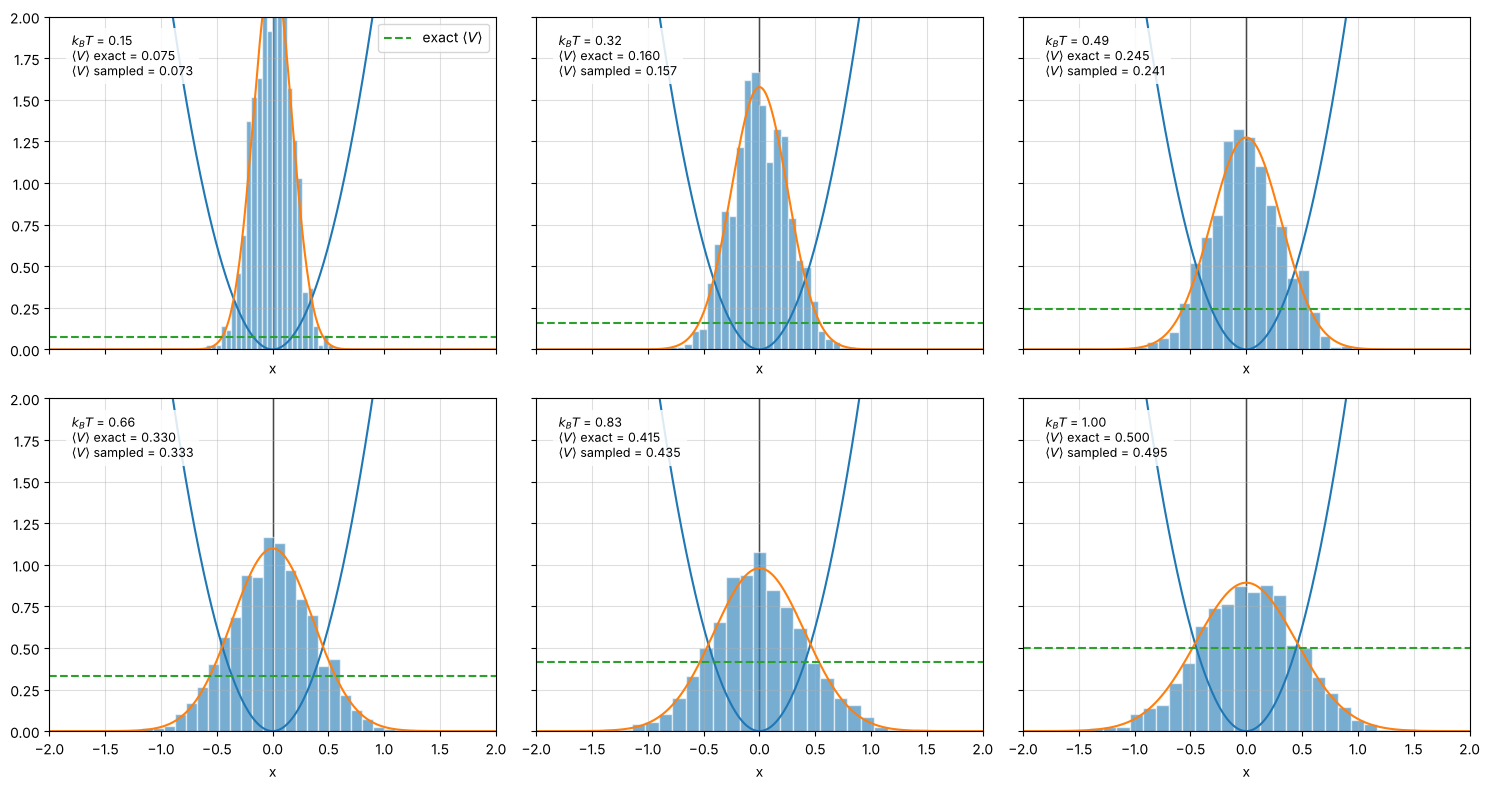

In [3]:
V, lims = harmonic(k=5), (-3, 3)
xs = np.linspace(-2, 2, 400)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, kT in zip(axes.flat, np.linspace(0.15, 1, 6)):
    sample = rejection_sample(V, kT, lims, n_trials=10_000, rng=rng)
    exact = thermal_average(V, kT, lims)
    ax.hist(sample, bins=25, density=True, color="C0", alpha=0.6, edgecolor="white")
    ax.plot(xs, V(xs), color="C0")
    ax.plot(xs, boltzmann_pdf(V, kT, lims)(xs), color="C1")
    ax.axhline(exact, color="C2", ls="--", label="exact $\\langle V\\rangle$")
    annotate(ax, f"$k_BT$ = {kT:.2f}\n$\\langle V\\rangle$ exact = {exact:.3f}\n$\\langle V\\rangle$ sampled = {V(sample).mean():.3f}")
    setup_axes(ax, xlim=(-2, 2), ylim=(0, 2), xlabel="x", ylabel=None)
axes[0, 0].legend(loc="upper right")
fig.tight_layout()
plt.show()